# Recurrent neural networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/rnn/rnn-notebook.ipynb)

Companion notebook for the *Recurrent neural networks* slides. Each idea is written first by hand
with NumPy and then checked with scikit-learn or with an independent computation.

**Data:** a synthetic sine wave with a little noise, cut into windows of $T$ steps; the target is the next value.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42
T = 10
HIDDEN = 8
LEARNING_RATE = 0.05
STEPS = 2000
CLIP = 1.0

rng = np.random.default_rng(RANDOM_STATE)
series = np.sin(np.arange(400) * 0.2) + 0.05 * rng.normal(size=400)
windows = np.lib.stride_tricks.sliding_window_view(series, T + 1)
X, y = windows[:, :T], windows[:, T]
X_train, X_test, y_train, y_test = X[:300], X[300:], y[:300], y[300:]

## 1. The recurrent cell

$\mathbf{h}_t = \tanh(\mathbf{W}_{hh}\mathbf{h}_{t-1} + \mathbf{W}_{xh}\mathbf{x}_t + \mathbf{b}_h)$, starting at $\mathbf{h}_0 = \mathbf{0}$.
The slide's example: one state number, $W_{xh} = 1$, $W_{hh} = 0.5$, inputs $1, 0, 1$.

In [2]:
h = 0.0
for x_t in [1, 0, 1]:
    h = np.tanh(0.5 * h + x_t)
    print(f"h = {h:.3f}")

unrolled = np.tanh(0.5 * np.tanh(0.5 * np.tanh(1) + 0) + 1)
print("same result:", np.isclose(h, unrolled))

h = 0.762
h = 0.363
h = 0.828
same result: True


## 2. Backpropagation through time

The network reads a window and predicts the next value from the last state, $\hat{y} = \mathbf{W}_{hy}\mathbf{h}_T + b_y$,
with squared error as the loss. Backpropagation runs back along the states, and the shared weights add up the gradients of all steps.

In [3]:
def forward(params: dict, X: np.ndarray) -> tuple[np.ndarray, list]:
    """Run the cell over every window (one row per window) and return predictions and states."""
    states = [np.zeros((len(X), HIDDEN))]
    for t in range(X.shape[1]):
        states.append(np.tanh(states[-1] @ params["W_hh"].T + X[:, [t]] @ params["W_xh"].T + params["b_h"]))
    return states[-1] @ params["W_hy"] + params["b_y"], states


def cost(params: dict, X: np.ndarray, y: np.ndarray) -> float:
    return np.mean((forward(params, X)[0] - y) ** 2)


def bptt(params: dict, X: np.ndarray, y: np.ndarray) -> dict:
    """Gradient of the cost by backpropagation through time."""
    y_hat, states = forward(params, X)
    d_y = 2 * (y_hat - y) / len(y)
    grads = {"W_hy": states[-1].T @ d_y, "b_y": d_y.sum(),
             "W_hh": 0, "W_xh": 0, "b_h": 0}
    d_h = np.outer(d_y, params["W_hy"])
    for t in range(X.shape[1], 0, -1):
        d_a = d_h * (1 - states[t] ** 2)
        grads["W_hh"] = grads["W_hh"] + d_a.T @ states[t - 1]
        grads["W_xh"] = grads["W_xh"] + d_a.T @ X[:, [t - 1]]
        grads["b_h"] = grads["b_h"] + d_a.sum(axis=0)
        d_h = d_a @ params["W_hh"]
    return grads


params = {"W_hh": rng.normal(0, 0.3, (HIDDEN, HIDDEN)), "W_xh": rng.normal(0, 0.5, (HIDDEN, 1)),
          "b_h": np.zeros(HIDDEN), "W_hy": rng.normal(0, 0.5, HIDDEN), "b_y": 0.0}

Independent check: nudge each weight of $\mathbf{W}_{hh}$ by a tiny $\varepsilon$ and measure how the cost changes.

In [4]:
eps = 1e-6
numeric = np.zeros_like(params["W_hh"])
for index in np.ndindex(numeric.shape):
    plus, minus = {**params, "W_hh": params["W_hh"].copy()}, {**params, "W_hh": params["W_hh"].copy()}
    plus["W_hh"][index] += eps
    minus["W_hh"][index] -= eps
    numeric[index] = (cost(plus, X_train, y_train) - cost(minus, X_train, y_train)) / (2 * eps)

print("same result:", np.allclose(bptt(params, X_train, y_train)["W_hh"], numeric, atol=1e-7))

same result: True


## 3. Vanishing and exploding gradients

With one state number, $\dfrac{\partial h_T}{\partial h_1} = \prod_{t=2}^{T} w_{hh}\,(1 - h_t^2)$: one factor per step.

In [5]:
def run_scalar(h_1: float, w_hh: float, inputs: np.ndarray) -> np.ndarray:
    states = [h_1]
    for x_t in inputs:
        states.append(np.tanh(w_hh * states[-1] + x_t))
    return np.array(states)


inputs = rng.normal(0, 0.5, 20)
states = run_scalar(0.1, 0.8, inputs)
product = np.prod(0.8 * (1 - states[1:] ** 2))
numeric = (run_scalar(0.1 + eps, 0.8, inputs)[-1] - run_scalar(0.1 - eps, 0.8, inputs)[-1]) / (2 * eps)
print(f"dh_T/dh_1 = {product:.2e} | same result:", np.isclose(product, numeric, rtol=1e-4))

dh_T/dh_1 = 1.13e-05 | same result: True


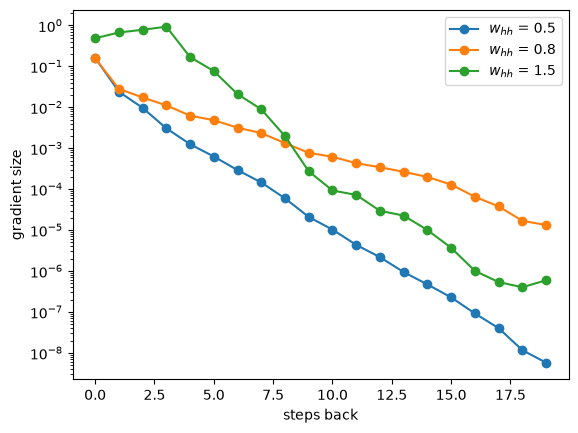

In [6]:
for w_hh in [0.5, 0.8, 1.5]:
    factors = w_hh * (1 - run_scalar(0.0, w_hh, inputs)[1:] ** 2)
    plt.semilogy(np.abs(np.cumprod(factors[::-1])), marker="o", label=f"$w_{{hh}}$ = {w_hh}")
plt.xlabel("steps back")
plt.ylabel("gradient size")
plt.legend()
plt.show()

## 4. Training and forecasting

Gradient descent with the BPTT gradient, $\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha \nabla J$.
Clipping scales a gradient longer than a threshold back to that length.
A Ridge regression on the same $T$ past values (lag features) is a reference forecaster.

In [7]:
for _ in range(STEPS):
    grads = bptt(params, X_train, y_train)
    norm = np.sqrt(sum(np.sum(g ** 2) for g in grads.values()))
    for name in params:
        params[name] = params[name] - LEARNING_RATE * grads[name] * min(1, CLIP / norm)

rnn_mse = mean_squared_error(y_test, forward(params, X_test)[0])
ridge_mse = mean_squared_error(y_test, Ridge(alpha=1.0).fit(X_train, y_train).predict(X_test))
last_value_mse = mean_squared_error(y_test, X_test[:, -1])
print(f"test MSE: RNN {rnn_mse:.4f}, Ridge {ridge_mse:.4f}, repeat last value {last_value_mse:.4f}")
print("both beat repeating the last value:", rnn_mse < last_value_mse and ridge_mse < last_value_mse)

test MSE: RNN 0.0050, Ridge 0.0033, repeat last value 0.0251
both beat repeating the last value: True


## 5. The LSTM cell

Gates $\mathbf{f}_t, \mathbf{i}_t, \mathbf{o}_t = \sigma(\mathbf{W}[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b})$ and candidate $\tilde{\mathbf{c}}_t = \tanh(\mathbf{W}_c[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_c)$;
then $\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t$ and $\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t)$.

In [8]:
def sigmoid(a: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-a))


W_f, W_i, W_o, W_c = rng.normal(0, 0.5, (4, HIDDEN, HIDDEN + 1))
h_prev, c_prev, x_t = rng.normal(size=HIDDEN), rng.normal(size=HIDDEN), np.array([0.7])
v = np.concatenate([h_prev, x_t])

f, i, o = sigmoid(W_f @ v), sigmoid(W_i @ v), sigmoid(W_o @ v)
c = f * c_prev + i * np.tanh(W_c @ v)
h = o * np.tanh(c)

Libraries stack the four weight matrices into one and do a single product per step. Same cell, one multiplication:

In [9]:
a_f, a_i, a_o, a_c = np.split(np.vstack([W_f, W_i, W_o, W_c]) @ v, 4)
c_stacked = sigmoid(a_f) * c_prev + sigmoid(a_i) * np.tanh(a_c)
print("same result:", np.allclose(h, sigmoid(a_o) * np.tanh(c_stacked)))

same result: True


## Exercises

1. Set `CLIP = 1e9` (no clipping) and `LEARNING_RATE = 0.5` in section 4. What happens to the RNN's test error?
2. In section 3, find the value of $w_{hh}$ where the gradient stops shrinking over 20 steps.
3. Write one GRU step, $\mathbf{h}_t = (1 - \mathbf{z}_t) \odot \mathbf{h}_{t-1} + \mathbf{z}_t \odot \tilde{\mathbf{h}}_t$, and check that $\mathbf{z}_t = \mathbf{0}$ copies the old state.